In [1]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('/content/WineQT.csv')

In [4]:
df


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,2
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,3
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595


In [5]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [7]:
le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [8]:
df_enc

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,25,74,0,10,39,9,28,305,62,17,10,2,0
1,29,110,0,20,61,23,61,246,31,29,15,2,1
2,29,86,4,17,55,13,48,260,37,26,15,2,2
3,62,12,56,10,38,15,54,315,27,19,15,3,3
4,25,74,0,10,39,9,28,305,62,17,10,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,14,40,13,17,39,27,34,166,53,36,30,3,1138
1139,19,58,8,10,31,26,32,226,53,43,11,3,1139
1140,13,54,8,11,53,30,38,105,56,19,24,2,1140
1141,10,45,10,15,25,38,45,119,63,37,33,3,1141


In [9]:
X = df_enc[['volatile acidity','citric acid','residual sugar','chlorides','free sulfur dioxide','total sulfur dioxide','density','pH','sulphates','alcohol','quality','Id']]
Y = df_enc['fixed acidity']

In [10]:
X

,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,74,0,10,39,9,28,305,62,17,10,2,0
1,110,0,20,61,23,61,246,31,29,15,2,1
2,86,4,17,55,13,48,260,37,26,15,2,2
3,12,56,10,38,15,54,315,27,19,15,3,3
4,74,0,10,39,9,28,305,62,17,10,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...
1138,40,13,17,39,27,34,166,53,36,30,3,1138
1139,58,8,10,31,26,32,226,53,43,11,3,1139
1140,54,8,11,53,30,38,105,56,19,24,2,1140
1141,45,10,15,25,38,45,119,63,37,33,3,1141


In [11]:
Y

,fixed acidity
0,25
1,29
2,29
3,62
4,25
...,...
1138,14
1139,19
1140,13
1141,10


In [12]:
model = CategoricalNB()
model.fit(X,Y)

CategoricalNB()

In [13]:
test = [[74,0,10,39,9,28,305,62,17,10,2,0]]

In [14]:
test

[[74, 0, 10, 39, 9, 28, 305, 62, 17, 10, 2, 0]]

In [17]:
print("-- Prediction ----------------------- ")
for t in test:
    # Convert the test list to a DataFrame with matching column names to suppress warnings
    row_df = pd.DataFrame([t], columns=X.columns)

    pred_encoded = model.predict(row_df)[0]
    pred_original = le['fixed acidity'].inverse_transform([pred_encoded])[0]
    prob = model.predict_proba(row_df)[0]

    print(f"Input Features : {t}")
    print(f"Predicted Class (Encoded): {pred_encoded}")
    print(f"Result (fixed acidity): {pred_original}")
    print(f"Top predicted probability: {max(prob):.4f}")

-- Prediction ----------------------- 
Input Features : [74, 0, 10, 39, 9, 28, 305, 62, 17, 10, 2, 0]
Predicted Class (Encoded): 25
Result (fixed acidity): 7.4
Top predicted probability: 0.9900


In [19]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X)
print(f"\nTraining Accuracy : {accuracy_score(Y, y_pred)*100:.2f}%")


Training Accuracy : 97.81%


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

/tmp/ipykernel_4596/1744190048.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index.astype(str), y=counts.values, ax=axes[0, 0], palette='viridis')


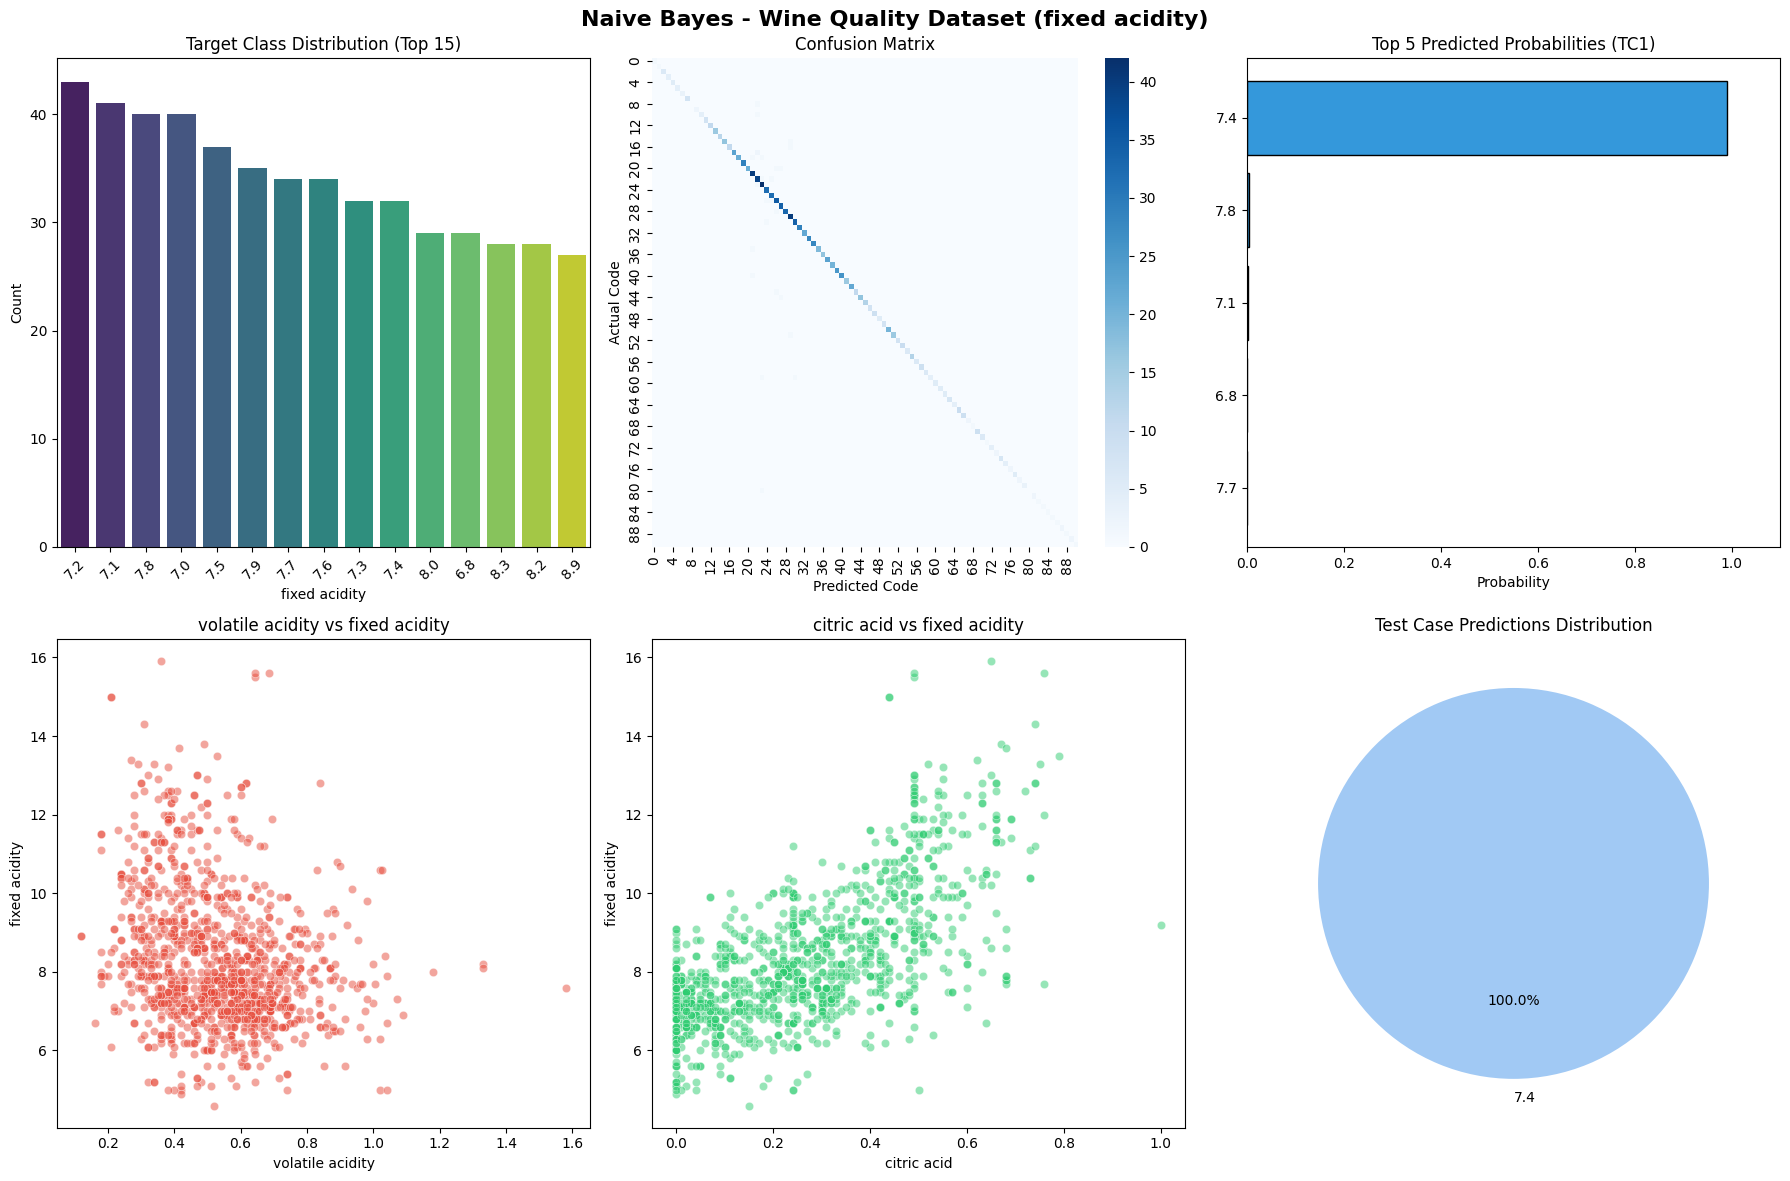

In [21]:
# Pre-calculate variables for the test predictions so the plots work
test_cases = test
predictions = []
probabilities = []

for t in test_cases:
    row_df = pd.DataFrame([t], columns=X.columns)
    pred_encoded = model.predict(row_df)[0]
    pred_original = le['fixed acidity'].inverse_transform([pred_encoded])[0]
    prob = model.predict_proba(row_df)[0]

    predictions.append(pred_original)
    probabilities.append(prob)

# --Plots------
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle("Naive Bayes - Wine Quality Dataset (fixed acidity)", fontsize=16, fontweight='bold')

# 1. Class Distribution (Top 15 most common fixed acidity classes for readability)
counts = df['fixed acidity'].value_counts().head(15)
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Target Class Distribution (Top 15)')
axes[0, 0].set_xlabel('fixed acidity')
axes[0, 0].set_ylabel('Count')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Confusion Matrix
cm = confusion_matrix(Y, model.predict(X))
# Displaying the confusion matrix as a heatmap (subsampled or simplified if class count is too high)
sns.heatmap(cm, cmap='Blues', cbar=True, ax=axes[0, 1])
axes[0, 1].set_title('Confusion Matrix')
axes[0, 1].set_xlabel('Predicted Code')
axes[0, 1].set_ylabel('Actual Code')

# 3. Prediction Probabilities for the first test case
if probabilities:
    classes = le['fixed acidity'].classes_
    # Show the top probabilities
    top_indices = np.argsort(probabilities[0])[-5:]
    top_probs = probabilities[0][top_indices]
    top_labels = [str(classes[idx]) for idx in top_indices]

    axes[0, 2].barh(top_labels, top_probs, color='#3498db', edgecolor='black')
    axes[0, 2].set_title("Top 5 Predicted Probabilities (TC1)")
    axes[0, 2].set_xlabel("Probability")
    axes[0, 2].set_xlim(0, 1.1)

# 4. volatile acidity vs fixed acidity (scatter plot representing relations)
sns.scatterplot(data=df, x='volatile acidity', y='fixed acidity', alpha=0.5, ax=axes[1, 0], color='#e74c3c')
axes[1, 0].set_title('volatile acidity vs fixed acidity')
axes[1, 0].set_xlabel('volatile acidity')
axes[1, 0].set_ylabel('fixed acidity')

# 5. citric acid vs fixed acidity
sns.scatterplot(data=df, x='citric acid', y='fixed acidity', alpha=0.5, ax=axes[1, 1], color='#2ecc71')
axes[1, 1].set_title('citric acid vs fixed acidity')
axes[1, 1].set_xlabel('citric acid')
axes[1, 1].set_ylabel('fixed acidity')

# 6. Pie Chart - Predictions distribution across test cases
pred_counts = pd.Series(predictions).value_counts()
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index.astype(str), autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
axes[1, 2].set_title('Test Case Predictions Distribution')

plt.tight_layout()
plt.show()